In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# Load the generated feature dataset

data_path = r"C:\ML PROJECT\generated_data\segmentation_features.csv"

df = pd.read_csv(data_path)

from IPython.display import display as show_table

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
show_table(df.head())

Dataset loaded successfully!
Dataset shape: (2192, 11)

First 5 rows:


,image_name,tumor_type,tumor_area,tumor_percentage,tumor_width,tumor_height,aspect_ratio,mean_intensity,std_intensity,min_intensity,max_intensity
0,enh_1841.png,Glioma,5973,2.278519,88,85,1.035294,118.261678,63.219609,1,242
1,enh_1842.png,Glioma,6523,2.488327,90,89,1.011236,116.281159,60.558850,1,236
2,enh_1843.png,Glioma,5800,2.212524,86,92,0.934783,114.764138,56.469622,1,236
3,enh_1844.png,Glioma,3352,1.278687,65,61,1.065574,103.958532,44.343451,13,212
4,enh_1845.png,Glioma,9911,3.780746,106,128,0.828125,149.474725,48.307842,1,254


In [4]:
# Separate input features and target variable

X = df.drop(columns=["image_name", "tumor_type"])
y = df["tumor_type"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

Features shape: (2192, 9)
Target shape: (2192,)

Feature columns:
['tumor_area', 'tumor_percentage', 'tumor_width', 'tumor_height', 'aspect_ratio', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']

Target classes:
<StringArray>
['Glioma', 'Meningioma', 'Pituitary tumor']
Length: 3, dtype: str


In [5]:
# Split data into training, validation, and test sets

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Dataset split completed!")

print("\nTraining:")
print("Features:", X_train.shape)
print("Labels:", y_train.shape)

print("\nValidation:")
print("Features:", X_val.shape)
print("Labels:", y_val.shape)

print("\nTest:")
print("Features:", X_test.shape)
print("Labels:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Dataset split completed!

Training:
Features: (1534, 9)
Labels: (1534,)

Validation:
Features: (329, 9)
Labels: (329,)

Test:
Features: (329, 9)
Labels: (329,)

Training class distribution:
tumor_type
Pituitary tumor    651
Meningioma         495
Glioma             388
Name: count, dtype: int64

Validation class distribution:
tumor_type
Pituitary tumor    140
Meningioma         106
Glioma              83
Name: count, dtype: int64

Test class distribution:
tumor_type
Pituitary tumor    139
Meningioma         107
Glioma              83
Name: count, dtype: int64


In [6]:
# Scale numerical features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed!")

print("\nTraining scaled shape:", X_train_scaled.shape)
print("Validation scaled shape:", X_val_scaled.shape)
print("Test scaled shape:", X_test_scaled.shape)

print("\nTraining scaled feature means:")
print(np.mean(X_train_scaled, axis=0))

print("\nTraining scaled feature standard deviations:")
print(np.std(X_train_scaled, axis=0))

Feature scaling completed!

Training scaled shape: (1534, 9)
Validation scaled shape: (329, 9)
Test scaled shape: (329, 9)

Training scaled feature means:
[-7.41113675e-17 -3.47397035e-17  1.32010873e-16  1.48222735e-16
  9.03232291e-17  3.58976936e-17 -4.72459968e-16  2.54757826e-17
  1.91647364e-16]

Training scaled feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [7]:
# Save the classification scaler for deployment

import joblib

classification_scaler_path = r"C:\ML PROJECT\models\classification_scaler.pkl"

joblib.dump(
    scaler,
    classification_scaler_path
)

print("Classification scaler saved successfully!")
print("File:", classification_scaler_path)

Classification scaler saved successfully!
File: C:\ML PROJECT\models\classification_scaler.pkl


# Review -1
1. Logistic Regression
2. KNN Classifier
3. Guassian Naive Bayes
4. Decision Tree Classifier
5. Support Vector Machine(SVM)

# 1. Logistic Regression

In [8]:
# Train Logistic Regression model

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [9]:
# Evaluate Logistic Regression on validation data

from sklearn.metrics import accuracy_score, classification_report

# Make predictions
y_val_pred = logistic_model.predict(X_val_scaled)

# Calculate accuracy
val_accuracy = accuracy_score(y_val, y_val_pred)

print("Logistic Regression Validation Accuracy:",
      f"{val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Logistic Regression Validation Accuracy: 0.6505

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.52      0.14      0.23        83
     Meningioma       0.60      0.86      0.71       106
Pituitary tumor       0.72      0.79      0.76       140

       accuracy                           0.65       329
      macro avg       0.61      0.60      0.56       329
   weighted avg       0.63      0.65      0.61       329



In [10]:
# Save final Logistic Regression model

import joblib

classification_model_path = r"C:\ML PROJECT\models\final_logistic_regression_model.pkl"

joblib.dump(logistic_model, classification_model_path)

print("Final Logistic Regression model saved successfully!")
print("File:", classification_model_path)

Final Logistic Regression model saved successfully!
File: C:\ML PROJECT\models\final_logistic_regression_model.pkl


# 2.KNN Classifier

In [11]:
# Train K-Nearest Neighbors (KNN) model

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(X_train_scaled, y_train)

print("KNN training completed!")

KNN training completed!


In [12]:
# Evaluate KNN on validation data

y_val_pred_knn = knn_model.predict(X_val_scaled)

knn_val_accuracy = accuracy_score(y_val, y_val_pred_knn)

print("KNN Validation Accuracy:",
      f"{knn_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_knn))

KNN Validation Accuracy: 0.6474

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.49      0.46      0.47        83
     Meningioma       0.62      0.75      0.68       106
Pituitary tumor       0.78      0.69      0.73       140

       accuracy                           0.65       329
      macro avg       0.63      0.63      0.63       329
   weighted avg       0.65      0.65      0.65       329



# 3. Guassian Naive Bayes

In [13]:
# Train Gaussian Naive Bayes model

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

print("Gaussian Naive Bayes training completed!")

Gaussian Naive Bayes training completed!


In [14]:
# Evaluate Gaussian Naive Bayes on validation data

y_val_pred_nb = nb_model.predict(X_val_scaled)

nb_val_accuracy = accuracy_score(y_val, y_val_pred_nb)

print("Gaussian Naive Bayes Validation Accuracy:",
      f"{nb_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_nb))

Gaussian Naive Bayes Validation Accuracy: 0.6049

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.36      0.24      0.29        83
     Meningioma       0.59      0.65      0.62       106
Pituitary tumor       0.70      0.79      0.74       140

       accuracy                           0.60       329
      macro avg       0.55      0.56      0.55       329
   weighted avg       0.58      0.60      0.59       329



# 4. Decision Tree Classifier

In [15]:
# Train Decision Tree model

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [16]:
# Evaluate Decision Tree on validation data

y_val_pred_dt = dt_model.predict(X_val)

dt_val_accuracy = accuracy_score(y_val, y_val_pred_dt)

print("Decision Tree Validation Accuracy:",
      f"{dt_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_dt))

Decision Tree Validation Accuracy: 0.6413

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.43      0.46      0.44        83
     Meningioma       0.69      0.75      0.72       106
Pituitary tumor       0.75      0.66      0.70       140

       accuracy                           0.64       329
      macro avg       0.62      0.63      0.62       329
   weighted avg       0.65      0.64      0.64       329



## Decision Tree Visualization

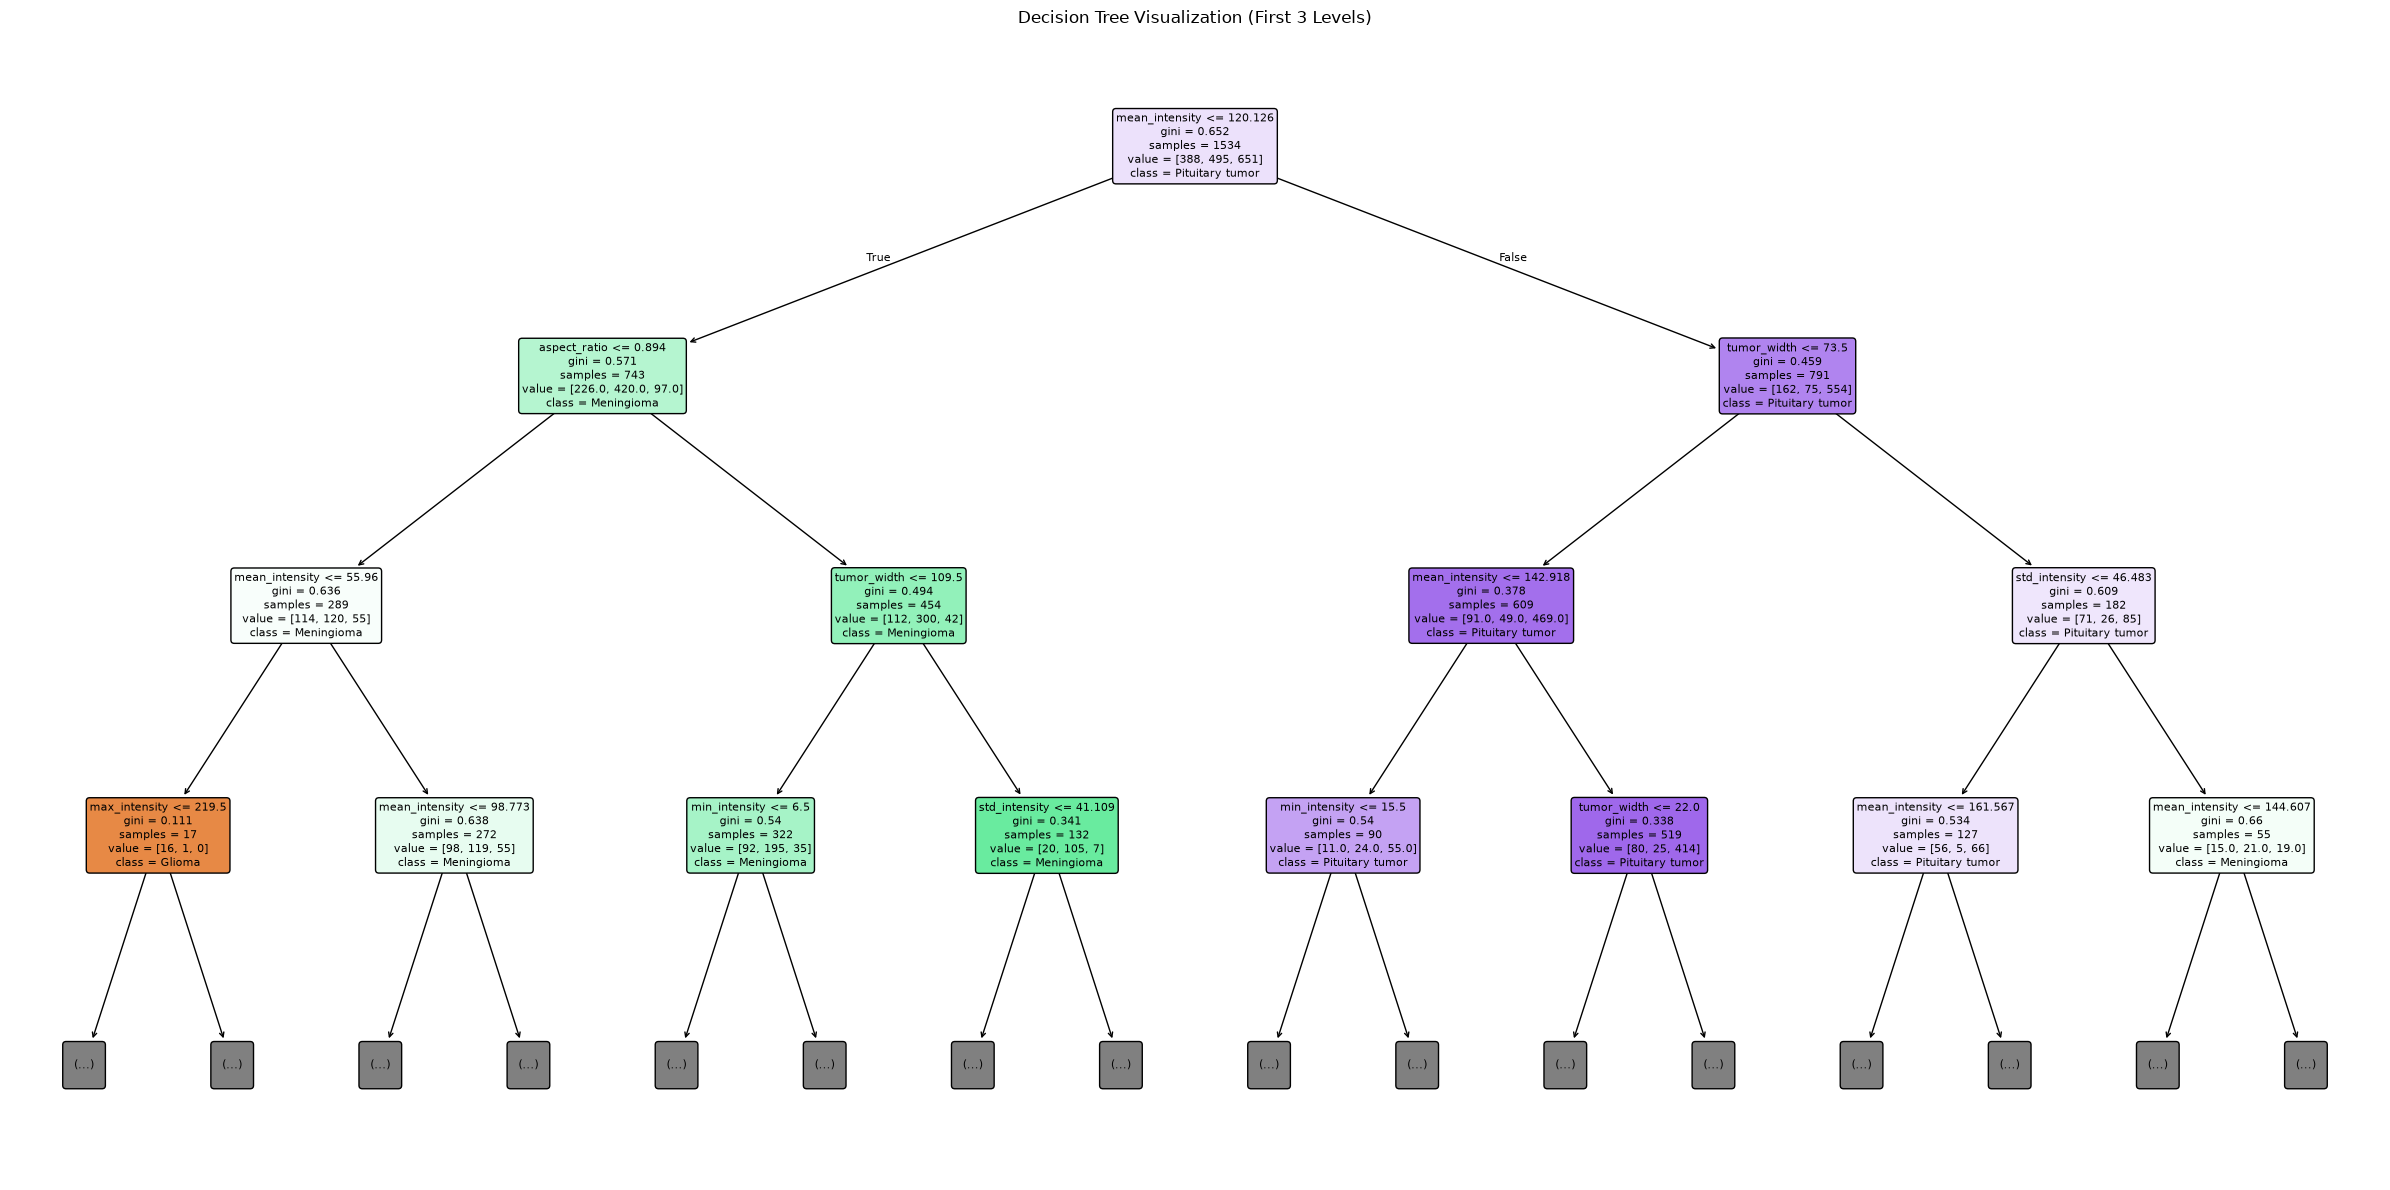

In [17]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Get the trained Decision Tree model
# Replace dt_model with your actual Decision Tree variable name if different.

plt.figure(figsize=(24, 12))

plot_tree(
    dt_model,
    feature_names=X_train.columns,
    class_names=[str(c) for c in dt_model.classes_],
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3
)

plt.title("Decision Tree Visualization (First 3 Levels)")
plt.tight_layout()
plt.show()

# 5. Support Vector Machine (SVM)

In [18]:
# Train Support Vector Machine (SVM) model

from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

print("SVM training completed!")

SVM training completed!


In [19]:
# Evaluate SVM on validation data

y_val_pred_svm = svm_model.predict(X_val_scaled)

svm_val_accuracy = accuracy_score(y_val, y_val_pred_svm)

print("SVM Validation Accuracy:",
      f"{svm_val_accuracy:.4f}")

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred_svm))

SVM Validation Accuracy: 0.6383

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.42      0.23      0.30        83
     Meningioma       0.60      0.78      0.68       106
Pituitary tumor       0.74      0.77      0.76       140

       accuracy                           0.64       329
      macro avg       0.59      0.59      0.58       329
   weighted avg       0.62      0.64      0.62       329



# Confusion Matrices for all 5 models

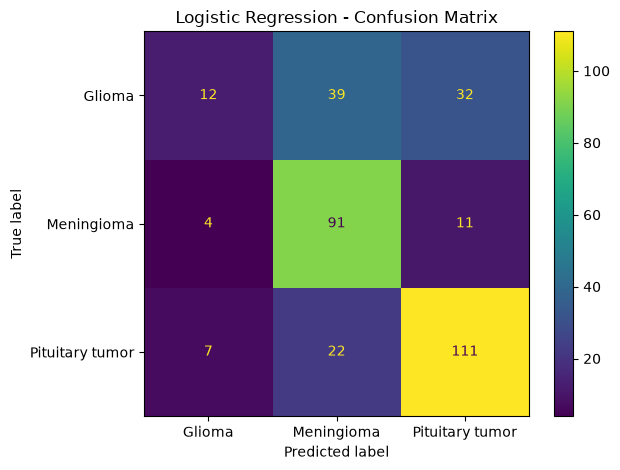

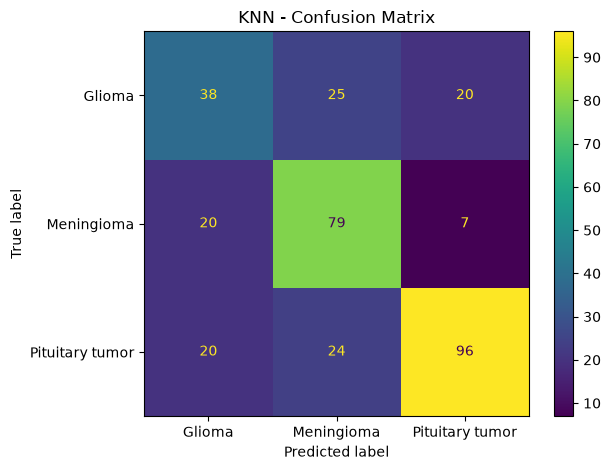

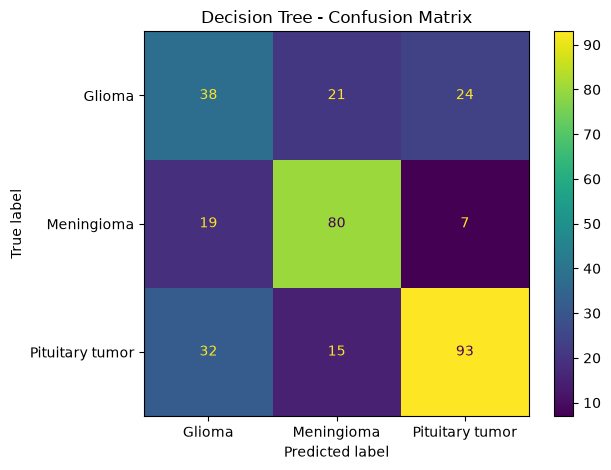

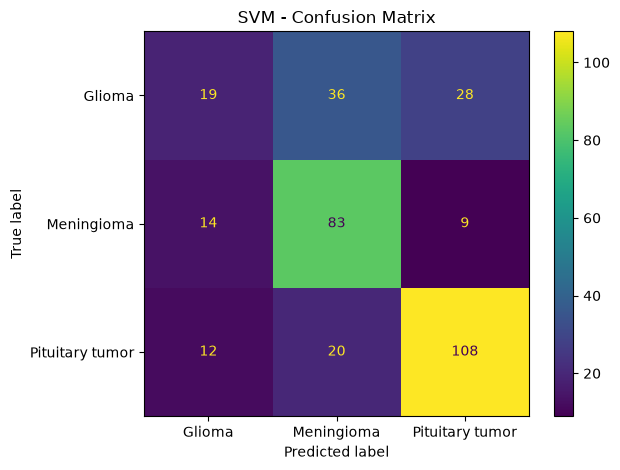

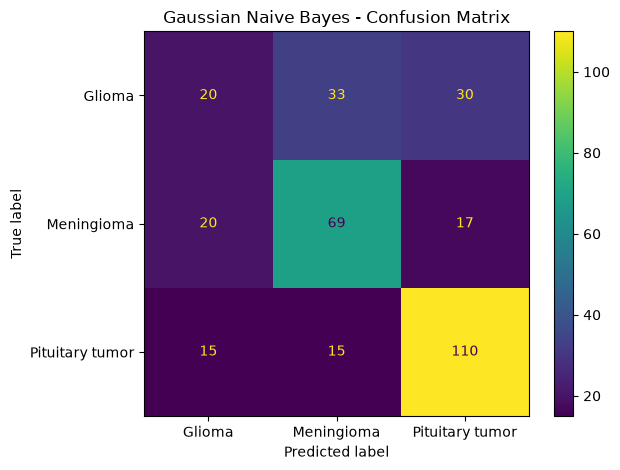

In [20]:
# Confusion matrices for all classification models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

classification_models = {
    "Logistic Regression": y_val_pred,
    "KNN": y_val_pred_knn,
    "Decision Tree": y_val_pred_dt,
    "SVM": y_val_pred_svm,
    "Gaussian Naive Bayes": y_val_pred_nb
}

for model_name, predictions in classification_models.items():

    cm = confusion_matrix(y_val, predictions)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Glioma", "Meningioma", "Pituitary tumor"]
    )

    disp.plot()

    plt.title(f"{model_name} - Confusion Matrix")
    plt.tight_layout()
    plt.show()

# Classification Model Comparison
Accuracy and Weighted F1-score

In [21]:
# Classification Model Comparison
# Accuracy and Weighted F1-score

from sklearn.metrics import accuracy_score, f1_score

classification_comparison = []

model_predictions = {
    "Logistic Regression": y_val_pred,
    "KNN": y_val_pred_knn,
    "Decision Tree": y_val_pred_dt,
    "SVM": y_val_pred_svm,
    "Gaussian Naive Bayes": y_val_pred_nb
}

for model_name, predictions in model_predictions.items():

    accuracy = accuracy_score(y_val, predictions)

    weighted_f1 = f1_score(
        y_val,
        predictions,
        average="weighted"
    )

    classification_comparison.append({
        "Model": model_name,
        "Validation Accuracy": round(accuracy, 4),
        "Weighted F1-Score": round(weighted_f1, 4)
    })

classification_comparison_df = pd.DataFrame(
    classification_comparison
)

classification_comparison_df = classification_comparison_df.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)


from IPython.display import display as show_table

print("Classification Model Comparison:")
show_table(classification_comparison_df)


Classification Model Comparison:


,Model,Validation Accuracy,Weighted F1-Score
0,Logistic Regression,0.6505,0.6057
1,KNN,0.6474,0.6473
2,Decision Tree,0.6413,0.6435
3,SVM,0.6383,0.6157
4,Gaussian Naive Bayes,0.6049,0.5877


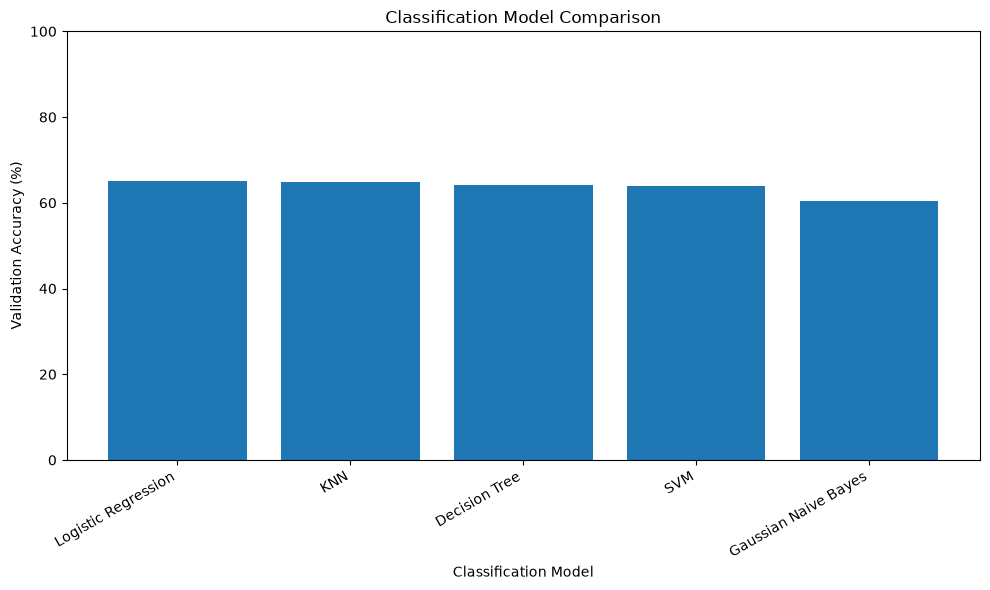

In [22]:
# Visualize model validation accuracy

plt.figure(figsize=(10, 6))

plt.bar(
    classification_comparison_df["Model"],
    classification_comparison_df["Validation Accuracy"] * 100
)

plt.xlabel("Classification Model")
plt.ylabel("Validation Accuracy (%)")
plt.title("Classification Model Comparison")
plt.xticks(rotation=30, ha="right")

plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [23]:
# Final evaluation on the unseen test set

from sklearn.metrics import accuracy_score, classification_report

# Logistic Regression
y_test_pred_lr = logistic_model.predict(X_test_scaled)
lr_test_accuracy = accuracy_score(y_test, y_test_pred_lr)

# KNN
y_test_pred_knn = knn_model.predict(X_test_scaled)
knn_test_accuracy = accuracy_score(y_test, y_test_pred_knn)

print("Logistic Regression Test Accuracy:",
      f"{lr_test_accuracy:.4f}")

print("\nLogistic Regression Test Classification Report:")
print(classification_report(y_test, y_test_pred_lr))

print("\n" + "=" * 60 + "\n")

print("KNN Test Accuracy:",
      f"{knn_test_accuracy:.4f}")

print("\nKNN Test Classification Report:")
print(classification_report(y_test, y_test_pred_knn))

Logistic Regression Test Accuracy: 0.6626

Logistic Regression Test Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.48      0.18      0.26        83
     Meningioma       0.66      0.80      0.73       107
Pituitary tumor       0.70      0.84      0.76       139

       accuracy                           0.66       329
      macro avg       0.61      0.61      0.58       329
   weighted avg       0.63      0.66      0.62       329



KNN Test Accuracy: 0.6596

KNN Test Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.46      0.46      0.46        83
     Meningioma       0.69      0.66      0.68       107
Pituitary tumor       0.76      0.78      0.77       139

       accuracy                           0.66       329
      macro avg       0.63      0.63      0.63       329
   weighted avg       0.66      0.66      0.66       329



In [24]:
# Save Logistic Regression test predictions

classification_test_results = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred_lr
})

classification_test_results.to_csv(
    r"C:\ML PROJECT\generated_data\logistic_test_predictions.csv",
    index=False
)

print("Classification test predictions saved successfully!")
print("File:", r"C:\ML PROJECT\generated_data\logistic_test_predictions.csv")

Classification test predictions saved successfully!
File: C:\ML PROJECT\generated_data\logistic_test_predictions.csv


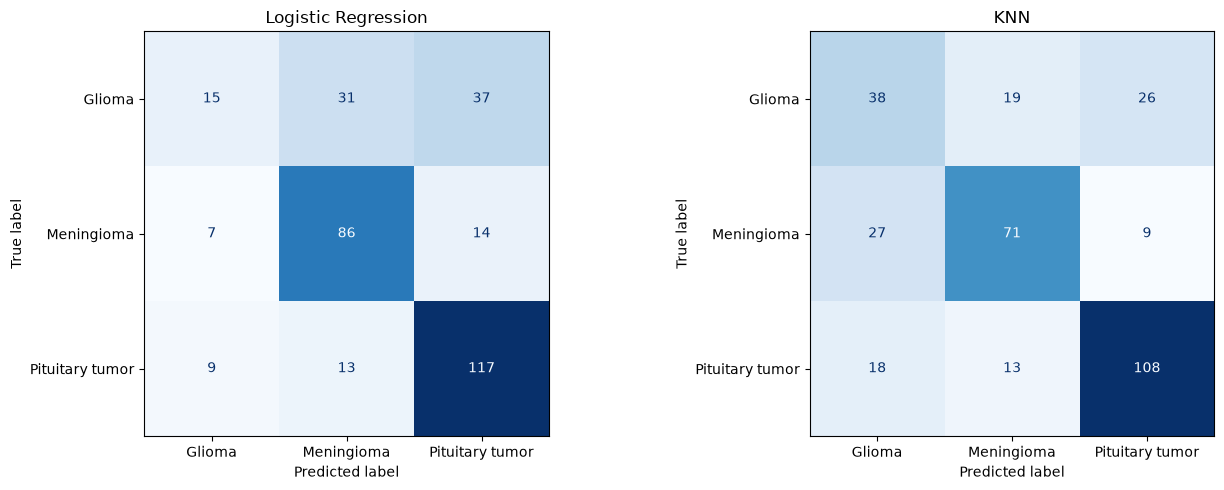

In [25]:
# Compare confusion matrices of Logistic Regression and KNN

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Logistic Regression confusion matrix
cm_lr = confusion_matrix(y_test, y_test_pred_lr)

# KNN confusion matrix
cm_knn = confusion_matrix(y_test, y_test_pred_knn)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression
disp_lr = ConfusionMatrixDisplay(
    confusion_matrix=cm_lr,
    display_labels=logistic_model.classes_
)
disp_lr.plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Logistic Regression")

# KNN
disp_knn = ConfusionMatrixDisplay(
    confusion_matrix=cm_knn,
    display_labels=knn_model.classes_
)
disp_knn.plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("KNN")

plt.tight_layout()
plt.show()

# Review -2 
6. Random Forest Classifier
7. AdaBoost Classifier
8. Gradient Boosting Classifier
9. Bagging Classifier
10. MLP Classifier

# 6. Random Forest Classifier 

In [26]:
# Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier

# Initialize the model
rf_classifier = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_classifier.fit(X_train, y_train)

# Predict on validation data
y_pred_rf = rf_classifier.predict(X_val)

# Evaluate the model
rf_accuracy = accuracy_score(y_val, y_pred_rf)

print("Random Forest Classifier")
print("Validation Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf))

Random Forest Classifier
Validation Accuracy: 0.7021276595744681

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.55      0.48      0.51        83
     Meningioma       0.69      0.79      0.74       106
Pituitary tumor       0.80      0.76      0.78       140

       accuracy                           0.70       329
      macro avg       0.68      0.68      0.68       329
   weighted avg       0.70      0.70      0.70       329



## Random Forest Feature Importance

,Feature,Importance
5,mean_intensity,0.2252
2,tumor_width,0.1194
8,max_intensity,0.1129
4,aspect_ratio,0.1093
6,std_intensity,0.1029
0,tumor_area,0.0863
1,tumor_percentage,0.0839
7,min_intensity,0.0812
3,tumor_height,0.0790


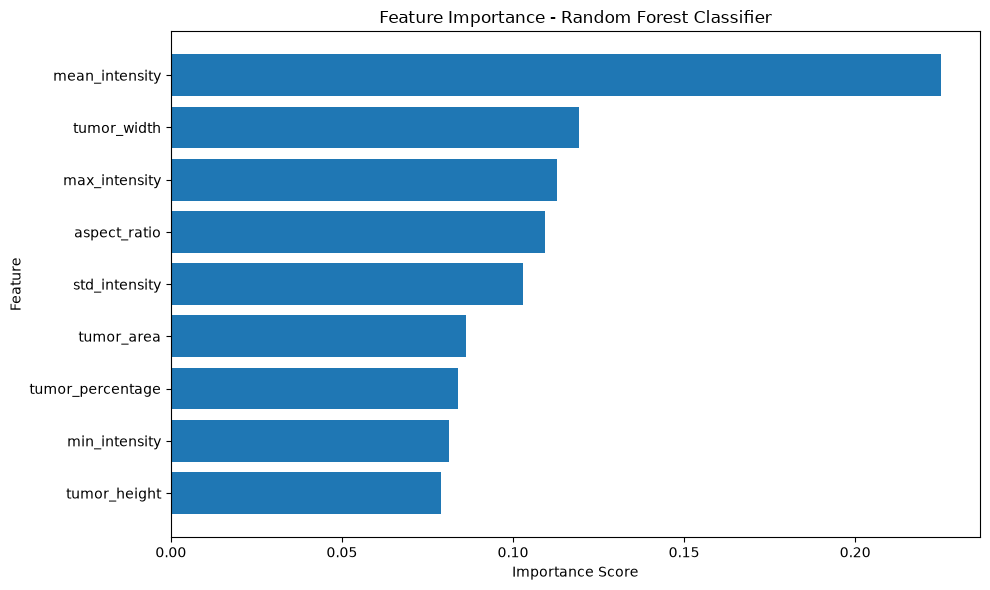

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract Random Forest feature importance
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_classifier.feature_importances_
}).sort_values(
    by="Importance",
    ascending=False
)

# Display importance scores
display(rf_importance.round(4))

# Plot feature importance
plt.figure(figsize=(10, 6))

plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)

plt.gca().invert_yaxis()
plt.title("Feature Importance - Random Forest Classifier")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

# 7. AdaBoost Classfier

In [25]:
# AdaBoost Classifier

from sklearn.ensemble import AdaBoostClassifier

# Initialize the model
adaboost_classifier = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)

# Train the model
adaboost_classifier.fit(X_train, y_train)

# Predict on validation data
y_pred_ada = adaboost_classifier.predict(X_val)

# Evaluate the model
ada_accuracy = accuracy_score(y_val, y_pred_ada)

print("AdaBoost Classifier")
print("Validation Accuracy:", ada_accuracy)

print("\nClassification Report:")
print(classification_report(y_val, y_pred_ada))

AdaBoost Classifier
Validation Accuracy: 0.6170212765957447

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.37      0.13      0.19        83
     Meningioma       0.58      0.78      0.67       106
Pituitary tumor       0.70      0.78      0.74       140

       accuracy                           0.62       329
      macro avg       0.55      0.56      0.53       329
   weighted avg       0.58      0.62      0.58       329



# 8. Gradient Boosting Classifier

In [26]:
# Gradient Boosting Classifier
from sklearn.ensemble import GradientBoostingClassifier

gb_classifier = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb_classifier.fit(X_train, y_train)

y_pred_gb = gb_classifier.predict(X_val)

gb_accuracy = accuracy_score(y_val, y_pred_gb)

print("Gradient Boosting Classifier")
print("Validation Accuracy:", gb_accuracy)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_gb))

Gradient Boosting Classifier
Validation Accuracy: 0.668693009118541

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.49      0.37      0.42        83
     Meningioma       0.68      0.75      0.72       106
Pituitary tumor       0.73      0.78      0.75       140

       accuracy                           0.67       329
      macro avg       0.64      0.64      0.63       329
   weighted avg       0.66      0.67      0.66       329



# 9.Bagging Classifier

In [27]:
# Bagging Classifier
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging_classifier = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)

bagging_classifier.fit(X_train, y_train)

y_pred_bagging = bagging_classifier.predict(X_val)

bagging_accuracy = accuracy_score(y_val, y_pred_bagging)

print("Bagging Classifier")
print("Validation Accuracy:", bagging_accuracy)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_bagging))

Bagging Classifier
Validation Accuracy: 0.6869300911854104

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.55      0.42      0.48        83
     Meningioma       0.71      0.82      0.76       106
Pituitary tumor       0.73      0.74      0.74       140

       accuracy                           0.69       329
      macro avg       0.66      0.66      0.66       329
   weighted avg       0.68      0.69      0.68       329



# 10. MLP Classifier

In [28]:
# MLP Classifier
from sklearn.neural_network import MLPClassifier

mlp_classifier = MLPClassifier(
    hidden_layer_sizes=(100, 50),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,
    random_state=42
)

mlp_classifier.fit(X_train_scaled, y_train)

y_pred_mlp = mlp_classifier.predict(X_val_scaled)

mlp_accuracy = accuracy_score(y_val, y_pred_mlp)

print("MLP Classifier")
print("Validation Accuracy:", mlp_accuracy)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_mlp))
print("Iterations used:", mlp_classifier.n_iter_)

MLP Classifier
Validation Accuracy: 0.6778115501519757

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.58      0.30      0.40        83
     Meningioma       0.66      0.83      0.74       106
Pituitary tumor       0.72      0.79      0.75       140

       accuracy                           0.68       329
      macro avg       0.65      0.64      0.63       329
   weighted avg       0.67      0.68      0.66       329

Iterations used: 35


# Consolidated Classification Model Evaluation

The ten classification algorithms implemented in Review 1 and Review 2 are evaluated using the same validation dataset to ensure a fair comparison. The evaluation considers Accuracy, Weighted Precision, Weighted Recall, and Weighted F1-Score.

Predictions from each model are stored for further analysis, including multiclass ROC-AUC evaluation using the One-vs-Rest (OvR) strategy and confusion matrix visualizations. These results will help identify promising models for hyperparameter tuning and final model selection.


In [29]:
# Collect predictions from all 10 classifiers

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": (logistic_model, X_val_scaled),
    "KNN": (knn_model, X_val_scaled),
    "Gaussian Naive Bayes": (nb_model, X_val_scaled),
    "Decision Tree": (dt_model, X_val),
    "SVC": (svm_model, X_val_scaled),
    "Random Forest": (rf_classifier, X_val),
    "AdaBoost": (adaboost_classifier, X_val),
    "Gradient Boosting": (gb_classifier, X_val),
    "Bagging": (bagging_classifier, X_val),
    "MLP": (mlp_classifier, X_val_scaled)
}

results = []
predictions = {}

for name, (model, X_data) in models.items():
    y_pred = model.predict(X_data)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision (Weighted)": precision_score(
            y_val, y_pred, average="weighted", zero_division=0
        ),
        "Recall (Weighted)": recall_score(
            y_val, y_pred, average="weighted", zero_division=0
        ),
        "F1-Score (Weighted)": f1_score(
            y_val, y_pred, average="weighted", zero_division=0
        )
    })

classification_results = pd.DataFrame(results)
classification_results

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted)
0,Logistic Regression,0.650456,0.631228,0.650456,0.605720
1,KNN,0.647416,0.653879,0.647416,0.647289
2,Gaussian Naive Bayes,0.604863,0.579890,0.604863,0.587715
3,Decision Tree,0.641337,0.649063,0.641337,0.643487
4,SVC,0.638298,0.615852,0.638298,0.615703
5,Random Forest,0.702128,0.699860,0.702128,0.699126
6,AdaBoost,0.617021,0.576834,0.617021,0.577307
7,Gradient Boosting,0.668693,0.655733,0.668693,0.659289
8,Bagging,0.686930,0.677512,0.686930,0.678808
9,MLP,0.677812,0.665790,0.677812,0.656883


# ROC-AUC Evaluation (One-vs-Rest)

In [30]:
from sklearn.metrics import roc_auc_score
import numpy as np

for name, (model, X_data) in models.items():

    try:
        if hasattr(model, "predict_proba"):
            y_scores = model.predict_proba(X_data)

        elif hasattr(model, "decision_function"):
            # Convert decision scores into normalized class scores
            decision_scores = model.decision_function(X_data)

            # Softmax transformation for multiclass scores
            exp_scores = np.exp(
                decision_scores - np.max(
                    decision_scores, axis=1, keepdims=True
                )
            )
            y_scores = exp_scores / exp_scores.sum(
                axis=1, keepdims=True
            )

        else:
            print(f"ROC-AUC not supported for {name}")
            continue

        auc_score = roc_auc_score(
            y_val,
            y_scores,
            labels=model.classes_,
            multi_class="ovr",
            average="weighted"
        )

        classification_results.loc[
            classification_results["Model"] == name,
            "ROC-AUC (OvR)"
        ] = auc_score

    except (ValueError, AttributeError) as e:
        print(f"ROC-AUC error for {name}: {e}")

classification_results

,Model,Accuracy,Precision (Weighted),Recall (Weighted),F1-Score (Weighted),ROC-AUC (OvR)
0,Logistic Regression,0.650456,0.631228,0.650456,0.605720,0.824777
1,KNN,0.647416,0.653879,0.647416,0.647289,0.809406
2,Gaussian Naive Bayes,0.604863,0.579890,0.604863,0.587715,0.787553
3,Decision Tree,0.641337,0.649063,0.641337,0.643487,0.733613
4,SVC,0.638298,0.615852,0.638298,0.615703,0.821566
5,Random Forest,0.702128,0.699860,0.702128,0.699126,0.856517
6,AdaBoost,0.617021,0.576834,0.617021,0.577307,0.792763
7,Gradient Boosting,0.668693,0.655733,0.668693,0.659289,0.839007
8,Bagging,0.686930,0.677512,0.686930,0.678808,0.856178
9,MLP,0.677812,0.665790,0.677812,0.656883,0.839790



# Confusion Matrix Analysis

Confusion matrices are used to examine the classification performance of all ten models by comparing actual tumor types with predicted tumor types. They help identify correctly classified samples and misclassifications among Pituitary, Meningioma, and Glioma classes.


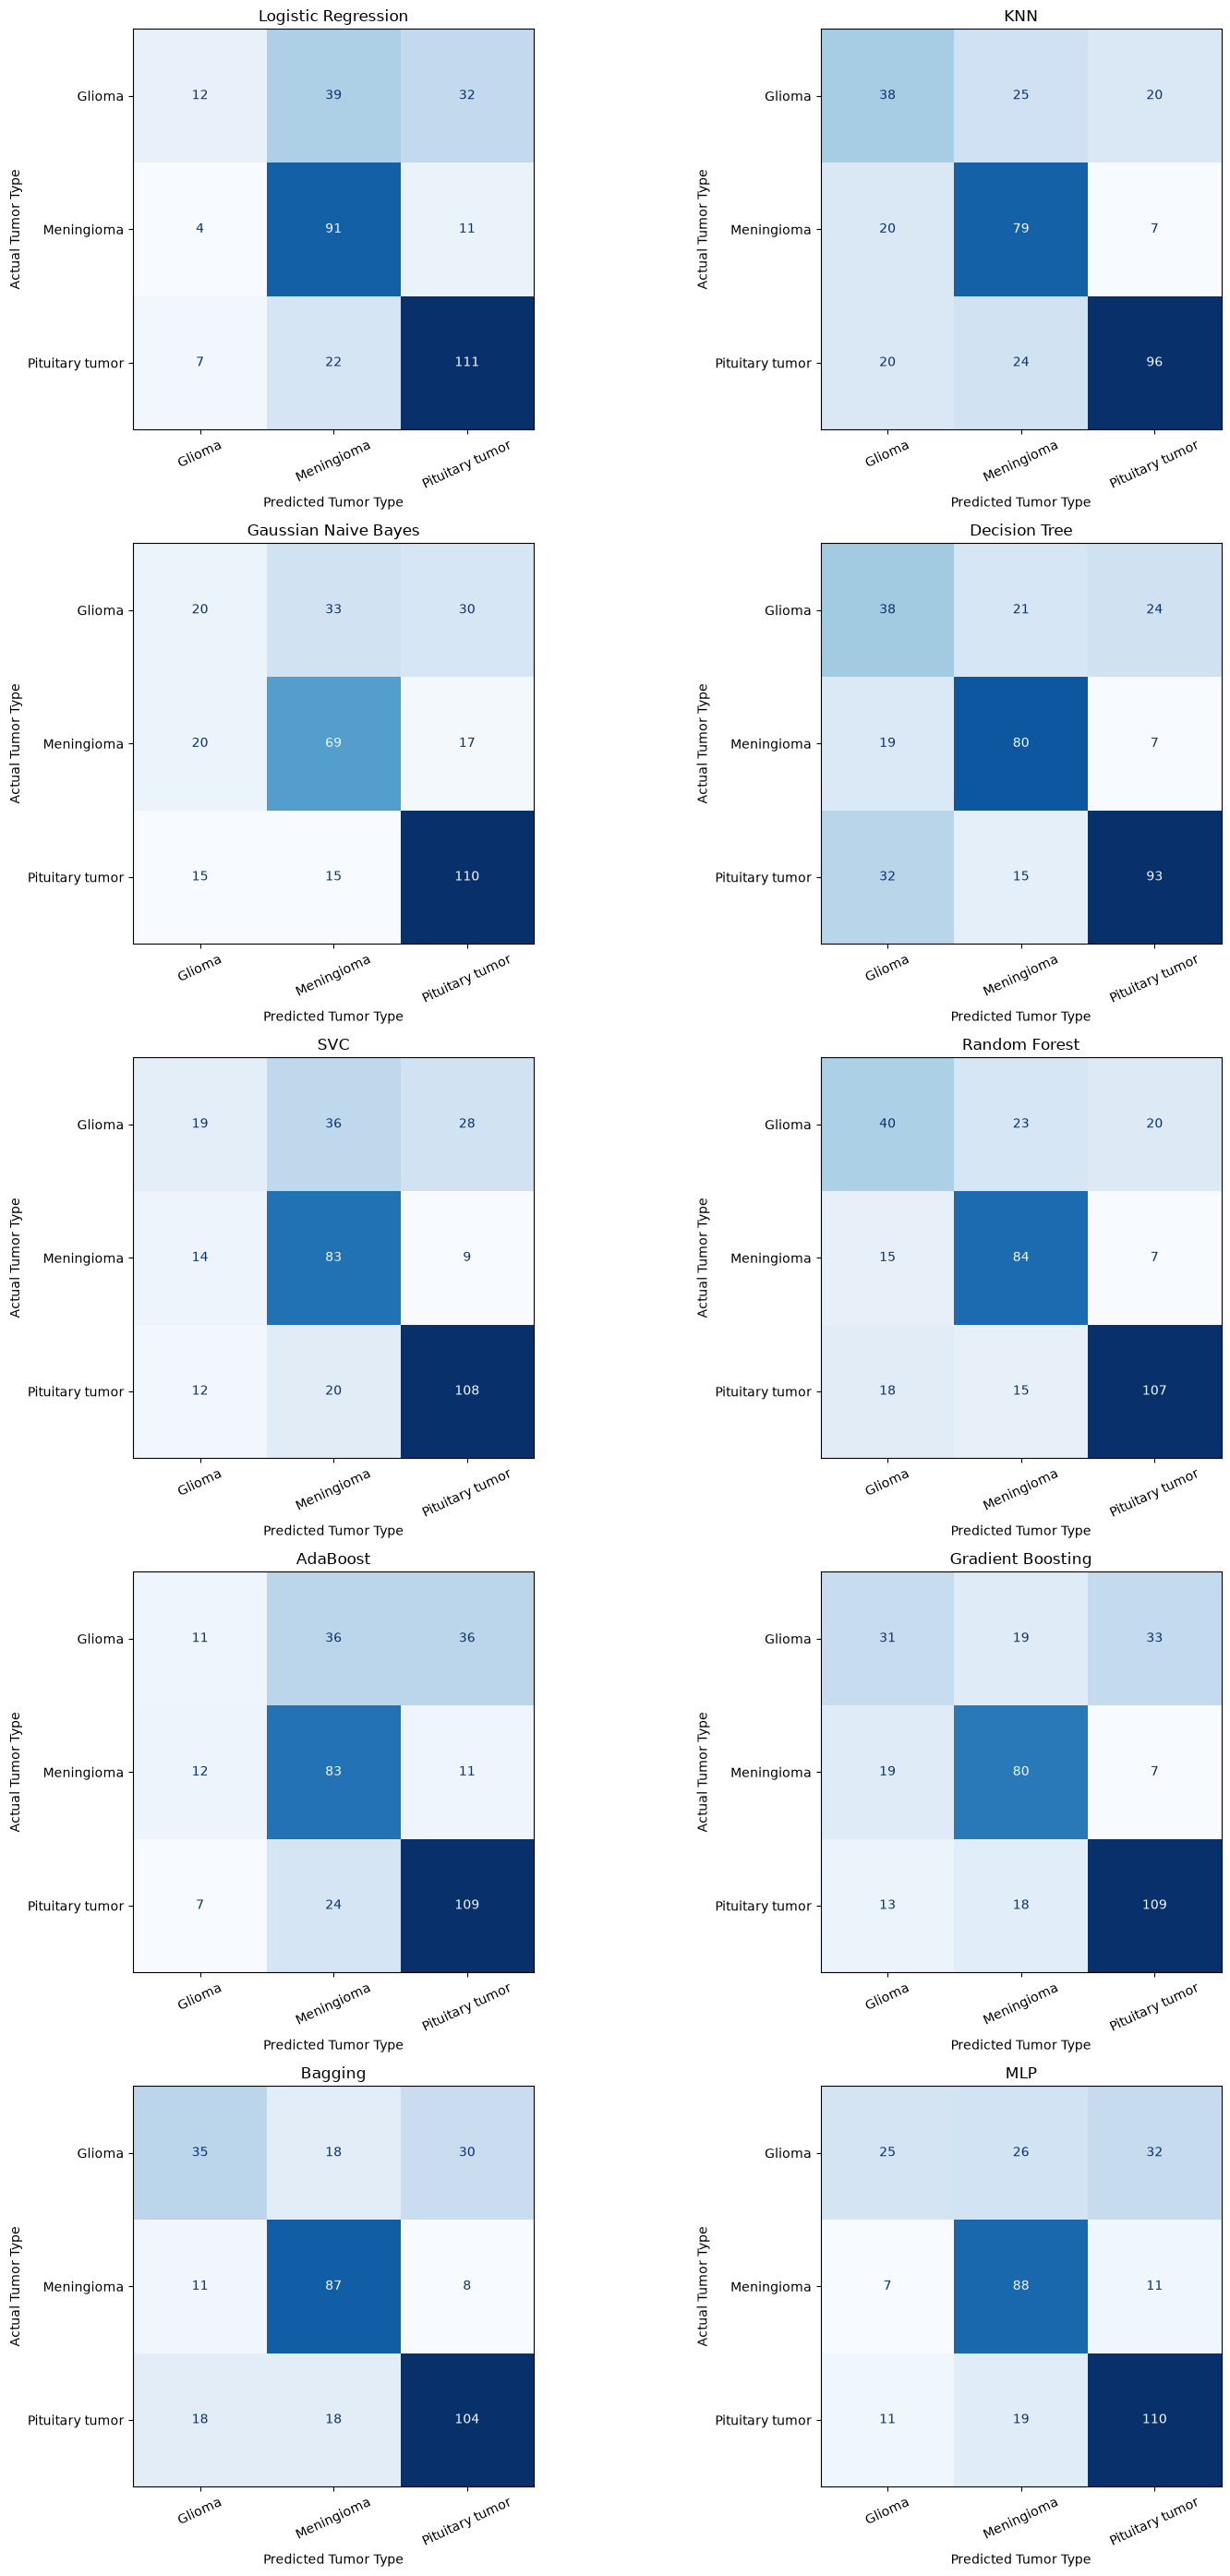

In [38]:
# Confusion Matrices for All 10 Classification Models

import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

class_names = ["Glioma", "Meningioma", "Pituitary tumor"]

fig, axes = plt.subplots(5, 2, figsize=(16, 28))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_val,
        y_pred,
        labels=class_names
    )

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display.plot(
        ax=axes[i],
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted Tumor Type")
    axes[i].set_ylabel("Actual Tumor Type")
    axes[i].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# Hyperparameter Tuning — Random Forest

Random Forest is selected as the initial candidate for hyperparameter tuning because it achieved the highest validation accuracy and weighted F1-score among the ten classification models. GridSearchCV is used to identify a better combination of hyperparameters through cross-validation, with weighted F1-score as the optimization metric.


In [39]:
# Hyperparameter Tuning for Random Forest

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

rf_grid_search = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    param_grid=rf_param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
    verbose=1
)

rf_grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(rf_grid_search.best_params_)

print("\nBest Cross-Validation Weighted F1-Score:")
print(rf_grid_search.best_score_)

best_rf = rf_grid_search.best_estimator_

y_pred_rf_tuned = best_rf.predict(X_val)

print("\nTuned Random Forest Validation Results")
print("Accuracy:", accuracy_score(y_val, y_pred_rf_tuned))
print(
    "Weighted F1-Score:",
    f1_score(y_val, y_pred_rf_tuned, average="weighted")
)
print("\nClassification Report:")
print(classification_report(y_val, y_pred_rf_tuned))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'max_depth': 20, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}

Best Cross-Validation Weighted F1-Score:
0.6735018539425318

Tuned Random Forest Validation Results
Accuracy: 0.7021276595744681
Weighted F1-Score: 0.6993709901997343

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.55      0.48      0.51        83
     Meningioma       0.68      0.80      0.74       106
Pituitary tumor       0.81      0.76      0.78       140

       accuracy                           0.70       329
      macro avg       0.68      0.68      0.68       329
   weighted avg       0.70      0.70      0.70       329




### Random Forest Tuning — Observation

GridSearchCV selected a Random Forest model with 200 estimators, a maximum depth of 20, a minimum of 5 samples required to split an internal node, and a minimum of 2 samples per leaf. The tuned model achieved a validation accuracy of approximately 70.21% and a weighted F1-score of 0.6994.

Compared with the baseline, the weighted F1-score improved only marginally. This suggests that the selected hyperparameters did not substantially improve validation performance. Further model comparisons are needed before selecting the final classifier.



# Hyperparameter Tuning — Gradient Boosting

Gradient Boosting is selected for hyperparameter tuning to evaluate whether adjusting the number of boosting stages, learning rate, and tree depth improves classification performance. GridSearchCV with five-fold cross-validation uses weighted F1-score to select the best hyperparameter combination.


In [40]:
# Hyperparameter Tuning for Gradient Boosting

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, f1_score, classification_report

gb_param_grid = {
    "n_estimators": [100, 200],
    "learning_rate": [0.05, 0.1],
    "max_depth": [2, 3],
    "min_samples_split": [2, 5]
}

gb_grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=gb_param_grid,
    scoring="f1_weighted",
    cv=5,
    n_jobs=-1,
    verbose=1
)

gb_grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(gb_grid_search.best_params_)

print("\nBest Cross-Validation Weighted F1-Score:")
print(gb_grid_search.best_score_)

best_gb = gb_grid_search.best_estimator_
y_pred_gb_tuned = best_gb.predict(X_val)

print("\nTuned Gradient Boosting Validation Results")
print("Accuracy:", accuracy_score(y_val, y_pred_gb_tuned))
print("Weighted F1-Score:",
      f1_score(y_val, y_pred_gb_tuned, average="weighted"))

print("\nClassification Report:")
print(classification_report(y_val, y_pred_gb_tuned))

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best Parameters:
{'learning_rate': 0.05, 'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 200}

Best Cross-Validation Weighted F1-Score:
0.6525826084453767

Tuned Gradient Boosting Validation Results
Accuracy: 0.6595744680851063
Weighted F1-Score: 0.6475732130274843

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.47      0.34      0.39        83
     Meningioma       0.66      0.75      0.70       106
Pituitary tumor       0.73      0.78      0.75       140

       accuracy                           0.66       329
      macro avg       0.62      0.62      0.62       329
   weighted avg       0.64      0.66      0.65       329



## Gradient Boosting Tuning — Observation

GridSearchCV selected a learning rate of 0.05, a maximum tree depth of 3, 2 minimum samples for splitting, and 200 boosting stages. The tuned model achieved a validation accuracy of approximately 65.96% and a weighted F1-score of 0.6476.

Compared with the baseline, both validation metrics decreased. Therefore, the tuned configuration did not improve generalization on the validation set. The baseline Gradient Boosting model remains preferable between these two configurations based on the current validation results.


# Baseline vs. Tuned Model Comparison

The tuned Random Forest and Gradient Boosting models are compared with their baseline versions using validation accuracy and weighted F1-score. This comparison helps determine whether hyperparameter tuning improves classification performance and supports final model selection.


In [41]:
# Compare Baseline and Tuned Models

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Random Forest (Baseline)",
        "Accuracy": accuracy_score(y_val, predictions["Random Forest"]),
        "Weighted F1": f1_score(
            y_val, predictions["Random Forest"], average="weighted"
        )
    },
    {
        "Model": "Random Forest (Tuned)",
        "Accuracy": accuracy_score(y_val, y_pred_rf_tuned),
        "Weighted F1": f1_score(
            y_val, y_pred_rf_tuned, average="weighted"
        )
    },
    {
        "Model": "Gradient Boosting (Baseline)",
        "Accuracy": accuracy_score(y_val, predictions["Gradient Boosting"]),
        "Weighted F1": f1_score(
            y_val, predictions["Gradient Boosting"], average="weighted"
        )
    },
    {
        "Model": "Gradient Boosting (Tuned)",
        "Accuracy": accuracy_score(y_val, y_pred_gb_tuned),
        "Weighted F1": f1_score(
            y_val, y_pred_gb_tuned, average="weighted"
        )
    }
])

model_comparison.sort_values(
    by="Weighted F1",
    ascending=False
).reset_index(drop=True)

,Model,Accuracy,Weighted F1
0,Random Forest (Tuned),0.702128,0.699371
1,Random Forest (Baseline),0.702128,0.699126
2,Gradient Boosting (Baseline),0.668693,0.659289
3,Gradient Boosting (Tuned),0.659574,0.647573


# Final Classification Model Selection

Random Forest with tuned hyperparameters is selected as the leading classification candidate because it achieved the highest validation accuracy and weighted F1-score among the baseline and tuned models compared. However, its improvement over the baseline is marginal. The selected model will be evaluated on the held-out test set to assess its final generalization performance.


Final Model: Tuned Random Forest
Test Accuracy: 0.6990881458966566
Test Precision (Weighted): 0.690878574561303
Test Recall (Weighted): 0.6990881458966566
Test F1-Score (Weighted): 0.6931721934984132

Classification Report:
                 precision    recall  f1-score   support

         Glioma       0.54      0.45      0.49        83
     Meningioma       0.70      0.77      0.73       107
Pituitary tumor       0.77      0.80      0.78       139

       accuracy                           0.70       329
      macro avg       0.67      0.67      0.67       329
   weighted avg       0.69      0.70      0.69       329



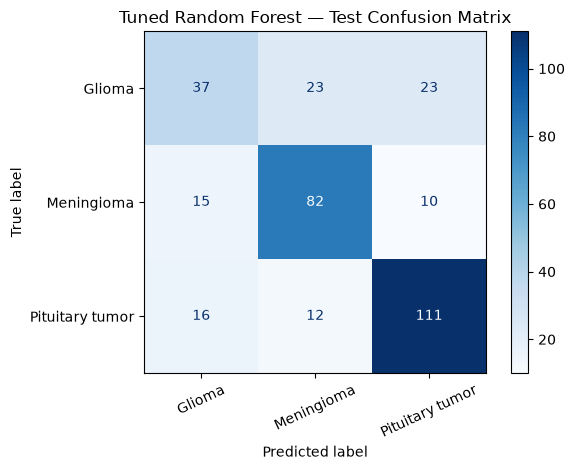

In [42]:
# Final Test Evaluation — Tuned Random Forest

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_pred_test = best_rf.predict(X_test)

print("Final Model: Tuned Random Forest")
print("Test Accuracy:", accuracy_score(y_test, y_pred_test))
print(
    "Test Precision (Weighted):",
    precision_score(y_test, y_pred_test, average="weighted", zero_division=0)
)
print(
    "Test Recall (Weighted):",
    recall_score(y_test, y_pred_test, average="weighted", zero_division=0)
)
print(
    "Test F1-Score (Weighted):",
    f1_score(y_test, y_pred_test, average="weighted", zero_division=0)
)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_test))

cm = confusion_matrix(
    y_test,
    y_pred_test,
    labels=best_rf.classes_
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_rf.classes_
)

display.plot(cmap="Blues", values_format="d")
plt.title("Tuned Random Forest — Test Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# Final Test Evaluation — Tuned Random Forest

The tuned Random Forest achieved a test accuracy of approximately 69.90% and a weighted F1-score of 0.6932. The confusion matrix indicates that the model classifies Pituitary tumor and Meningioma samples more effectively than Glioma samples. Glioma has the lowest recall, indicating that further improvements in class discrimination may be beneficial.

These results represent the model's performance on the held-out test set and provide the final evaluation of the selected classifier.


In [43]:
# Final Test ROC-AUC — Tuned Random Forest

from sklearn.metrics import roc_auc_score

y_test_proba = best_rf.predict_proba(X_test)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba,
    labels=best_rf.classes_,
    multi_class="ovr",
    average="weighted"
)

print("Tuned Random Forest Test ROC-AUC (OvR):", test_roc_auc)

Tuned Random Forest Test ROC-AUC (OvR): 0.8549867354117211
